
# Multi-Machine Sound Anomaly Detection Using Deep Learning

## Objective
To detect abnormal sounds produced by industrial machines using Deep Learning.

## Dataset
MIMII Industrial Machine Sound Dataset.

## Initial Machine
Industrial Fan.

## Main Model
CNN Autoencoder.

## Evaluation
ROC-AUC, Precision, Recall and F1-score.


In [1]:
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf

print("Project environment ready!")
print("TensorFlow:", tf.__version__)

Project environment ready!
TensorFlow: 2.21.0


In [2]:
from pathlib import Path

downloads_path = Path.home() / "Downloads"

files = list(downloads_path.glob("*0_dB_fan*"))

for file in files:
    print("Name:", file.name)
    print("Path:", file)
    print("Size (GB):", round(file.stat().st_size / (1024**3), 2))
    print("-" * 50)

Name: 0_dB_fan (2).zip
Path: C:\Users\hanum\Downloads\0_dB_fan (2).zip
Size (GB): 9.7
--------------------------------------------------
Name: 0_dB_fan.zip
Path: C:\Users\hanum\Downloads\0_dB_fan.zip
Size (GB): 9.7
--------------------------------------------------


In [3]:
import zipfile

zip_path = r"C:\Users\hanum\Downloads\0_dB_fan.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    files = z.infolist()

    print("Total items:", len(files))
    print("\nFirst 20 items:")

    for file in files[:20]:
        print(file.filename, "|", round(file.file_size / (1024**2), 2), "MB")

Total items: 5563

First 20 items:
fan/ | 0.0 MB
fan/id_00/ | 0.0 MB
fan/id_00/abnormal/ | 0.0 MB
fan/id_00/abnormal/00000000.wav | 2.44 MB
fan/id_00/abnormal/00000001.wav | 2.44 MB
fan/id_00/abnormal/00000002.wav | 2.44 MB
fan/id_00/abnormal/00000003.wav | 2.44 MB
fan/id_00/abnormal/00000004.wav | 2.44 MB
fan/id_00/abnormal/00000005.wav | 2.44 MB
fan/id_00/abnormal/00000006.wav | 2.44 MB
fan/id_00/abnormal/00000007.wav | 2.44 MB
fan/id_00/abnormal/00000008.wav | 2.44 MB
fan/id_00/abnormal/00000009.wav | 2.44 MB
fan/id_00/abnormal/00000010.wav | 2.44 MB
fan/id_00/abnormal/00000011.wav | 2.44 MB
fan/id_00/abnormal/00000012.wav | 2.44 MB
fan/id_00/abnormal/00000013.wav | 2.44 MB
fan/id_00/abnormal/00000014.wav | 2.44 MB
fan/id_00/abnormal/00000015.wav | 2.44 MB
fan/id_00/abnormal/00000016.wav | 2.44 MB


In [4]:
import zipfile
from collections import Counter

zip_path = r"C:\Users\hanum\Downloads\0_dB_fan.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    counts = Counter()

    for name in z.namelist():
        if name.endswith(".wav"):
            parts = name.split("/")
            machine_id = parts[1]
            label = parts[2]
            counts[(machine_id, label)] += 1

    for key, count in sorted(counts.items()):
        print(key, ":", count)

('id_00', 'abnormal') : 407
('id_00', 'normal') : 1011
('id_02', 'abnormal') : 359
('id_02', 'normal') : 1016
('id_04', 'abnormal') : 348
('id_04', 'normal') : 1033
('id_06', 'abnormal') : 361
('id_06', 'normal') : 1015


In [5]:
import zipfile
from pathlib import Path

zip_path = Path.home() / "Downloads" / "0_dB_fan.zip"

extract_path = Path.cwd() / "dataset" / "raw"
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: c:\Users\hanum\Machine-Sound-Anomaly-Detection\dataset\raw


In [6]:
from pathlib import Path

data_path = Path.cwd() / "dataset" / "raw" / "fan"

wav_files = list(data_path.rglob("*.wav"))

print("Total WAV files:", len(wav_files))
print("Sample file:", wav_files[0])

Total WAV files: 5550
Sample file: c:\Users\hanum\Machine-Sound-Anomaly-Detection\dataset\raw\fan\id_06\abnormal\00000000.wav


Sample Rate: 16000
Duration: 10.0 seconds
Audio Shape: (160000,)


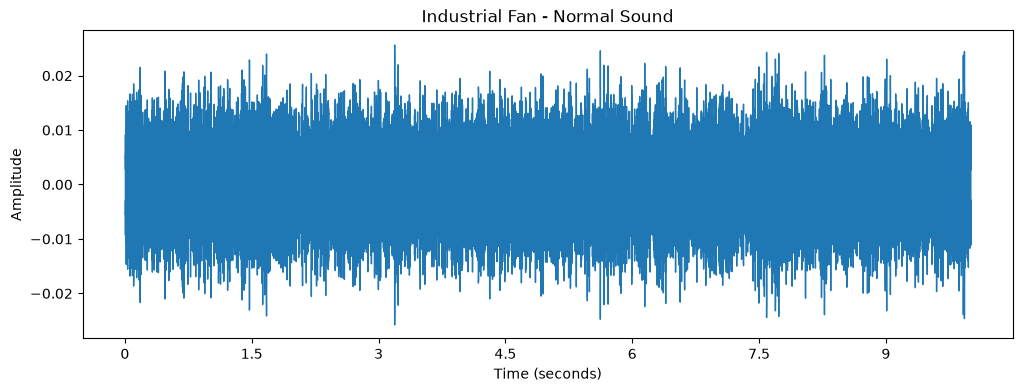

In [12]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Load one normal audio file
audio_path = next(data_path.glob("id_00/normal/*.wav"))

audio, sr = librosa.load(audio_path, sr=None)

print("Sample Rate:", sr)
print("Duration:", len(audio) / sr, "seconds")
print("Audio Shape:", audio.shape)

# Plot waveform
plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title("Industrial Fan - Normal Sound")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

Sample Rate: 16000
Duration: 10.0
Shape: (160000, 8)


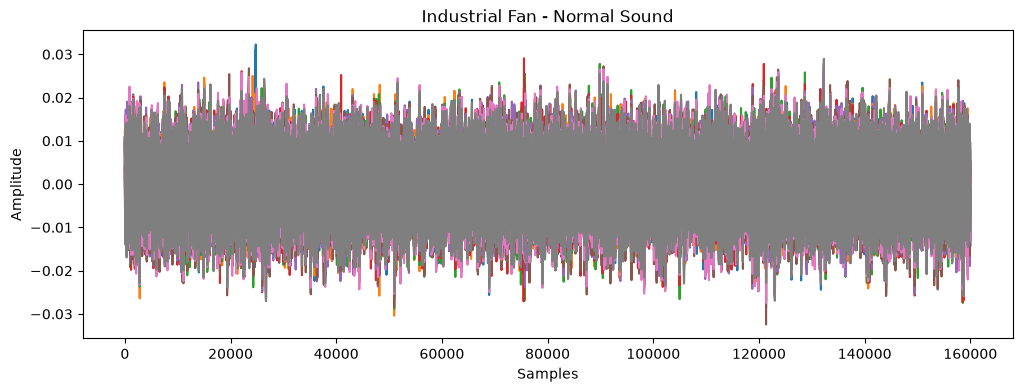

In [8]:
import soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path

audio_path = next(data_path.glob("id_00/normal/*.wav"))

audio, sr = sf.read(audio_path)

print("Sample Rate:", sr)
print("Duration:", len(audio) / sr)
print("Shape:", audio.shape)

plt.figure(figsize=(12, 4))
plt.plot(audio)
plt.title("Industrial Fan - Normal Sound")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

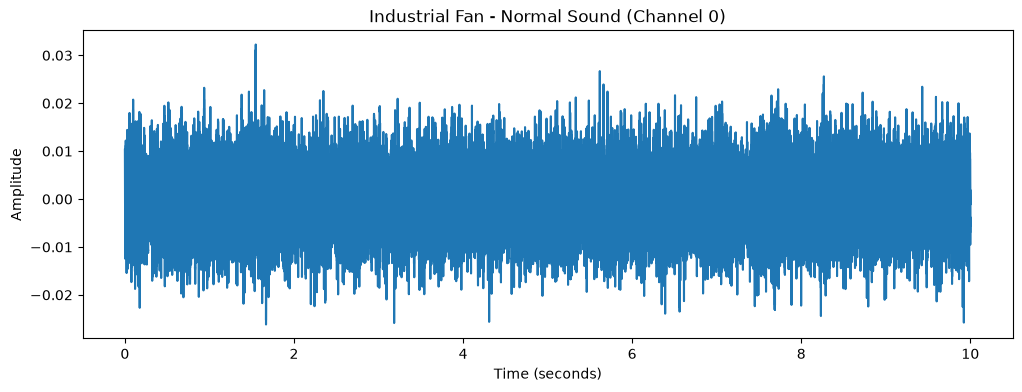

Audio shape: (160000,)


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Select microphone channel 0
audio_mono = audio[:, 0]

# Create time axis
time = np.arange(len(audio_mono)) / sr

# Plot waveform
plt.figure(figsize=(12, 4))
plt.plot(time, audio_mono)

plt.title("Industrial Fan - Normal Sound (Channel 0)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

print("Audio shape:", audio_mono.shape)

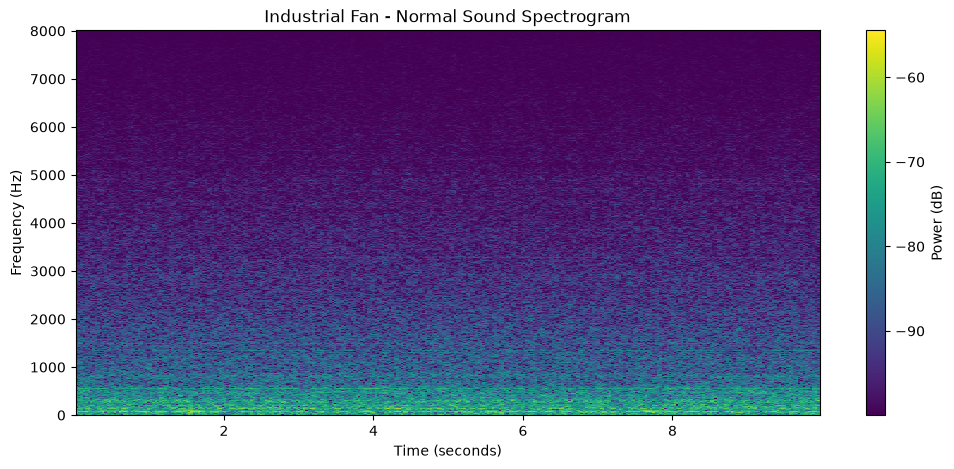

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

frequencies, times, Sxx = spectrogram(
    audio_mono,
    fs=sr,
    nperseg=1024,
    noverlap=512
)

plt.figure(figsize=(12, 5))

plt.pcolormesh(
    times,
    frequencies,
    10 * np.log10(Sxx + 1e-10),
    shading="auto"
)

plt.title("Industrial Fan - Normal Sound Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Power (dB)")
plt.show()

Librosa version: 1.0.1


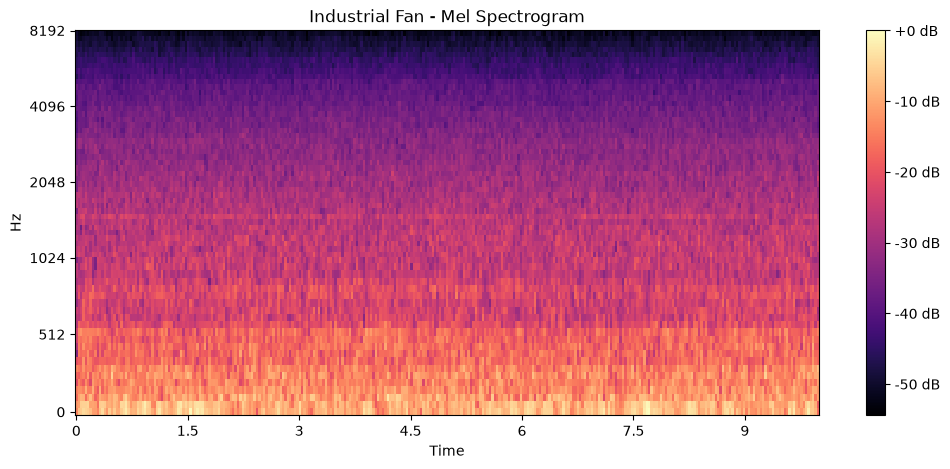

In [13]:
import librosa
import librosa.display

print("Librosa version:", librosa.__version__)

# Generate Mel Spectrogram
mel = librosa.feature.melspectrogram(
    y=audio_mono,
    sr=sr,
    n_fft=1024,
    hop_length=512,
    n_mels=64
)

# Convert to decibels
mel_db = librosa.power_to_db(mel, ref=np.max)

# Display
plt.figure(figsize=(12, 5))
librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Industrial Fan - Mel Spectrogram")
plt.show()

Normal shape: (64, 313)
Abnormal shape: (64, 313)


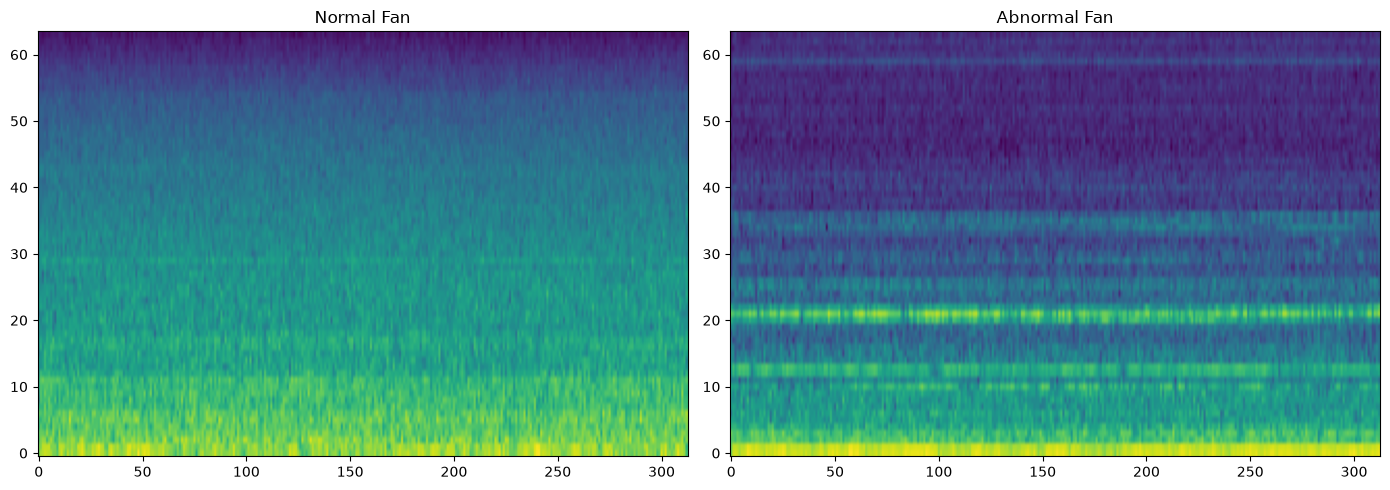

In [14]:
import librosa
import librosa.display
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# Function to convert audio into Log-Mel Spectrogram
def extract_logmel(file_path):

    audio, sr = sf.read(file_path)

    # Select microphone channel 0
    if audio.ndim == 2:
        audio = audio[:, 0]

    # Generate Mel Spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio.astype(np.float32),
        sr=sr,
        n_fft=1024,
        hop_length=512,
        n_mels=64
    )

    # Convert to Log scale
    log_mel = librosa.power_to_db(mel, ref=1.0)

    return log_mel


# Get one normal and one abnormal audio file
normal_path = next(data_path.glob("id_00/normal/*.wav"))
abnormal_path = next(data_path.glob("id_00/abnormal/*.wav"))

# Extract features
normal_mel = extract_logmel(normal_path)
abnormal_mel = extract_logmel(abnormal_path)

print("Normal shape:", normal_mel.shape)
print("Abnormal shape:", abnormal_mel.shape)

# Visualize both
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(normal_mel, origin="lower", aspect="auto")
axes[0].set_title("Normal Fan")

axes[1].imshow(abnormal_mel, origin="lower", aspect="auto")
axes[1].set_title("Abnormal Fan")

plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path
import pandas as pd

records = []

for machine_id in ["id_00", "id_02", "id_04", "id_06"]:

    for label in ["normal", "abnormal"]:

        folder = data_path / machine_id / label

        for file in folder.glob("*.wav"):

            records.append({
                "file_path": str(file),
                "machine_id": machine_id,
                "label": label
            })

df = pd.DataFrame(records)

print("Total recordings:", len(df))
print("\nLabel counts:")
print(df["label"].value_counts())

print("\nMachine counts:")
print(df.groupby(["machine_id", "label"]).size())

df.head()

Total recordings: 5550

Label counts:
label
normal      4075
abnormal    1475
Name: count, dtype: int64

Machine counts:
machine_id  label   
id_00       abnormal     407
            normal      1011
id_02       abnormal     359
            normal      1016
id_04       abnormal     348
            normal      1033
id_06       abnormal     361
            normal      1015
dtype: int64


,file_path,machine_id,label
0,c:\Users\hanum\Machine-Sound-Anomaly-Detection...,id_00,normal
1,c:\Users\hanum\Machine-Sound-Anomaly-Detection...,id_00,normal
2,c:\Users\hanum\Machine-Sound-Anomaly-Detection...,id_00,normal
3,c:\Users\hanum\Machine-Sound-Anomaly-Detection...,id_00,normal
4,c:\Users\hanum\Machine-Sound-Anomaly-Detection...,id_00,normal


In [16]:
import numpy as np
import pandas as pd

train_list = []
val_list = []
test_list = []

rng = np.random.default_rng(42)

for machine_id in df["machine_id"].unique():

    machine_df = df[df["machine_id"] == machine_id]

    # Only normal recordings for training and validation
    normal = machine_df[machine_df["label"] == "normal"]

    normal = normal.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    n = len(normal)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_list.append(normal.iloc[:train_end])
    val_list.append(normal.iloc[train_end:val_end])
    test_list.append(normal.iloc[val_end:])

    # All abnormal recordings go to testing
    abnormal = machine_df[machine_df["label"] == "abnormal"]
    test_list.append(abnormal)

# Combine datasets
train_df = pd.concat(train_list).reset_index(drop=True)
val_df = pd.concat(val_list).reset_index(drop=True)
test_df = pd.concat(test_list).reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTesting labels:")
print(test_df["label"].value_counts())

Training: 2851
Validation: 611
Testing: 2088

Training labels:
label
normal    2851
Name: count, dtype: int64

Validation labels:
label
normal    611
Name: count, dtype: int64

Testing labels:
label
abnormal    1475
normal       613
Name: count, dtype: int64


In [17]:
import numpy as np
from pathlib import Path

# Extract spectrograms from multiple audio files
def process_dataset(dataframe):

    features = []
    labels = []

    for i, row in enumerate(dataframe.itertuples()):

        mel = extract_logmel(row.file_path)

        features.append(mel)
        labels.append(0 if row.label == "normal" else 1)

        if (i + 1) % 100 == 0:
            print(f"Processed: {i + 1}/{len(dataframe)}")

    return np.array(features, dtype=np.float32), np.array(labels)


# Select fan id_00
train_00 = train_df[train_df["machine_id"] == "id_00"]
val_00 = val_df[val_df["machine_id"] == "id_00"]
test_00 = test_df[test_df["machine_id"] == "id_00"]

# Extract features
X_train, y_train = process_dataset(train_00)
X_val, y_val = process_dataset(val_00)
X_test, y_test = process_dataset(test_00)

print("\nFeature shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Processed: 100/707
Processed: 200/707
Processed: 300/707
Processed: 400/707
Processed: 500/707
Processed: 600/707
Processed: 700/707
Processed: 100/152
Processed: 100/559
Processed: 200/559
Processed: 300/559
Processed: 400/559
Processed: 500/559

Feature shapes:
Training: (707, 64, 313)
Validation: (152, 64, 313)
Testing: (559, 64, 313)


In [18]:
# Calculate statistics using training data only
mean = X_train.mean()
std = X_train.std()

# Normalize all datasets
X_train = (X_train - mean) / (std + 1e-8)
X_val = (X_val - mean) / (std + 1e-8)
X_test = (X_test - mean) / (std + 1e-8)

# Add channel dimension for CNN
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nMean:", X_train.mean())
print("Std:", X_train.std())

Training: (707, 64, 313, 1)
Validation: (152, 64, 313, 1)
Testing: (559, 64, 313, 1)

Mean: 4.964652e-08
Std: 1.0


In [19]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Input
input_layer = layers.Input(shape=(64, 313, 1))

# ENCODER
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(input_layer)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
encoded = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)

# DECODER
x = layers.UpSampling2D()(encoded)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)

x = layers.UpSampling2D()(x)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

x = layers.UpSampling2D()(x)
x = layers.Conv2D(1, 3, padding="same")(x)

# Match original width: 320 -> 313
output_layer = layers.Cropping2D(cropping=((0, 0), (0, 7)))(x)

# Create model
autoencoder = Model(input_layer, output_layer)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 313, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 157, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 79, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 40, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 80, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 80, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 160, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 160, 32)    │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 320, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 320, 1)     │           289 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cropping2d (Cropping2D)         │ (None, 64, 313, 1)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 185,217 (723.50 KB)

 Trainable params: 185,217 (723.50 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=30,
    batch_size=32,
    shuffle=True,
    validation_data=(X_val, X_val)
)


Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 541ms/step - loss: 0.2629 - val_loss: 0.1169
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 254ms/step - loss: 0.1020 - val_loss: 0.0923
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 296ms/step - loss: 0.0895 - val_loss: 0.0845
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 292ms/step - loss: 0.0821 - val_loss: 0.0776
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - loss: 0.0762 - val_loss: 0.0723
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - loss: 0.0705 - val_loss: 0.0674
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - loss: 0.0675 - val_loss: 0.0652
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - loss: 0.0654 - val_loss: 0.0634
Epoch 9/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 29s 721ms/step - loss: 0.0646 - val_loss: 0.0648
Epoch 10/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - loss: 0.0626 - val_loss: 0.0605
Epoch 11/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 24s 377ms/step - loss: 0.0606 - val_loss: 0.0596
Epoch 12/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 302ms/step - loss

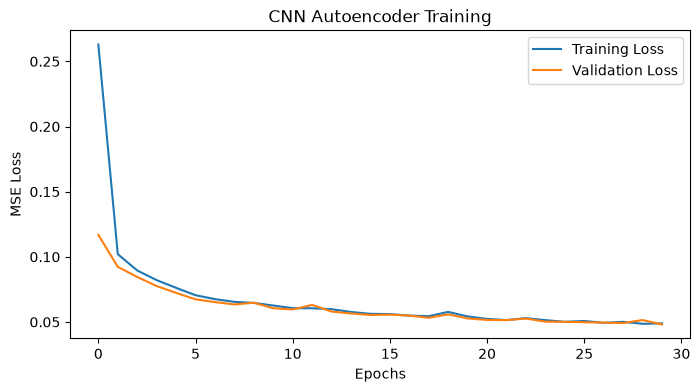

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("CNN Autoencoder Training")
plt.legend()
plt.show()

In [22]:
# Reconstruct test spectrograms
X_test_pred = autoencoder.predict(X_test)

# Calculate reconstruction error for each recording
test_errors = np.mean(
    np.square(X_test - X_test_pred),
    axis=(1, 2, 3)
)

print("Total test recordings:", len(test_errors))
print("Mean reconstruction error:", test_errors.mean())
print("Minimum error:", test_errors.min())
print("Maximum error:", test_errors.max())

18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step
Total test recordings: 559
Mean reconstruction error: 0.048064623
Minimum error: 0.04248861
Maximum error: 0.08280111


In [23]:
# Reconstruct validation recordings
X_val_pred = autoencoder.predict(X_val)

# Calculate validation reconstruction errors
val_errors = np.mean(
    np.square(X_val - X_val_pred),
    axis=(1, 2, 3)
)

# Calculate threshold using normal validation data
threshold = np.percentile(val_errors, 95)

print("Validation mean error:", val_errors.mean())
print("Anomaly threshold:", threshold)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Validation mean error: 0.04805355
Anomaly threshold: 0.05271853


In [24]:
# Predict using fixed threshold
y_pred = (test_errors > threshold).astype(int)

print("Threshold:", threshold)
print("Predicted Normal:", np.sum(y_pred == 0))
print("Predicted Abnormal:", np.sum(y_pred == 1))

Threshold: 0.05271853
Predicted Normal: 525
Predicted Abnormal: 34


In [25]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    accuracy_score
)

# Actual labels vs predicted labels
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Abnormal"]
))

# ROC-AUC using continuous reconstruction errors
auc = roc_auc_score(y_test, test_errors)

print("ROC-AUC:", auc)
print("Accuracy:", accuracy_score(y_test, y_pred))

Confusion Matrix:
[[137  15]
 [388  19]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.26      0.90      0.40       152
    Abnormal       0.56      0.05      0.09       407

    accuracy                           0.28       559
   macro avg       0.41      0.47      0.25       559
weighted avg       0.48      0.28      0.17       559

ROC-AUC: 0.4992241044872624
Accuracy: 0.27906976744186046


Normal error statistics:
count    152.000000
mean       0.048425
std        0.004582
min        0.043663
25%        0.045661
50%        0.047276
75%        0.049687
max        0.082801
dtype: float64

Abnormal error statistics:
count    407.000000
mean       0.047930
std        0.003154
min        0.042489
25%        0.045623
50%        0.047734
75%        0.049480
max        0.071517
dtype: float64


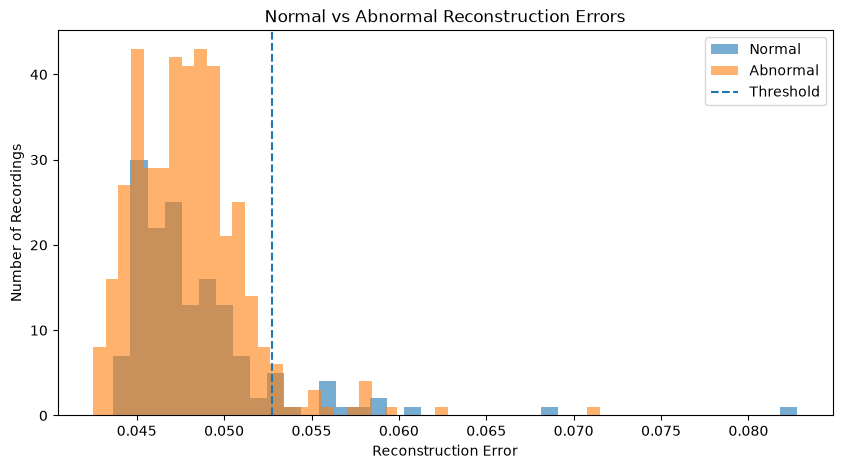

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# Separate reconstruction errors by actual class
normal_errors = test_errors[y_test == 0]
abnormal_errors = test_errors[y_test == 1]

print("Normal error statistics:")
print(pd.Series(normal_errors).describe())

print("\nAbnormal error statistics:")
print(pd.Series(abnormal_errors).describe())

# Visualize distributions
plt.figure(figsize=(10, 5))

plt.hist(normal_errors, bins=40, alpha=0.6, label="Normal")
plt.hist(abnormal_errors, bins=40, alpha=0.6, label="Abnormal")

plt.axvline(threshold, linestyle="--", label="Threshold")

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Recordings")
plt.title("Normal vs Abnormal Reconstruction Errors")
plt.legend()
plt.show()

In [27]:
# Recover original Log-Mel features
X_train_raw = X_train * std + mean
X_val_raw = X_val * std + mean
X_test_raw = X_test * std + mean

# Calculate statistics per Mel frequency
freq_mean = X_train_raw.mean(axis=(0, 2, 3), keepdims=True)
freq_std = X_train_raw.std(axis=(0, 2, 3), keepdims=True)

# Normalize
X_train = (X_train_raw - freq_mean) / (freq_std + 1e-8)
X_val = (X_val_raw - freq_mean) / (freq_std + 1e-8)
X_test = (X_test_raw - freq_mean) / (freq_std + 1e-8)

print("New training shape:", X_train.shape)
print("Mean:", X_train.mean())
print("Standard deviation:", X_train.std())

New training shape: (707, 64, 313, 1)
Mean: 3.3428657e-07
Standard deviation: 1.0


In [28]:
from tensorflow.keras.callbacks import EarlyStopping

# Rebuild model with fresh weights
autoencoder = Model(input_layer, output_layer)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Train again
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=30,
    batch_size=32,
    shuffle=True,
    validation_data=(X_val, X_val),
    callbacks=[early_stop]
)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 315ms/step - loss: 0.5799 - val_loss: 0.3950
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 254ms/step - loss: 0.3727 - val_loss: 0.3368
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 249ms/step - loss: 0.3231 - val_loss: 0.3079
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 250ms/step - loss: 0.3032 - val_loss: 0.2954
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 250ms/step - loss: 0.2937 - val_loss: 0.2900
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 259ms/step - loss: 0.2875 - val_loss: 0.2831
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 266ms/step - loss: 0.2832 - val_loss: 0.2798
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 257ms/step - loss: 0.2787 - val_loss: 0.2769
Epoch 9/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 254ms/step - loss: 0.2791 - val_loss: 0.2736
Epoch 10/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 253ms/step - loss: 0.2728 - val_loss: 0.2690
Epoch 11/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 257ms/step - loss: 0.2678 - val_loss: 0.2661
Epoch 12/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 256ms/step

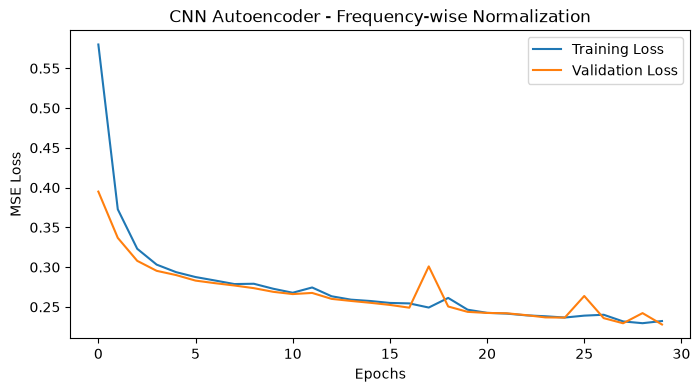

In [29]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Autoencoder - Frequency-wise Normalization")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [30]:
# 1. Reconstruct validation and test data
val_pred = autoencoder.predict(X_val)
test_pred = autoencoder.predict(X_test)

# 2. Calculate reconstruction errors
val_errors = np.mean(
    np.square(X_val - val_pred),
    axis=(1, 2, 3)
)

test_errors = np.mean(
    np.square(X_test - test_pred),
    axis=(1, 2, 3)
)

# 3. Calculate threshold using normal validation data
threshold = np.percentile(val_errors, 95)

# 4. Predict anomalies
y_pred = (test_errors > threshold).astype(int)

print("New threshold:", threshold)
print("Mean validation error:", val_errors.mean())
print("Mean test error:", test_errors.mean())

print("\nPredicted Normal:", np.sum(y_pred == 0))
print("Predicted Abnormal:", np.sum(y_pred == 1))

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step
New threshold: 0.2492703
Mean validation error: 0.22787927
Mean test error: 0.22903393

Predicted Normal: 519
Predicted Abnormal: 40


In [31]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Abnormal"]
))

print("New ROC-AUC:", roc_auc_score(y_test, test_errors))

              precision    recall  f1-score   support

      Normal       0.27      0.91      0.41       152
    Abnormal       0.68      0.07      0.12       407

    accuracy                           0.30       559
   macro avg       0.47      0.49      0.27       559
weighted avg       0.56      0.30      0.20       559

New ROC-AUC: 0.5337029613345403


Normal mean: 0.22947976
Abnormal mean: 0.22886744
Normal median: 0.22425017
Abnormal median: 0.22750326


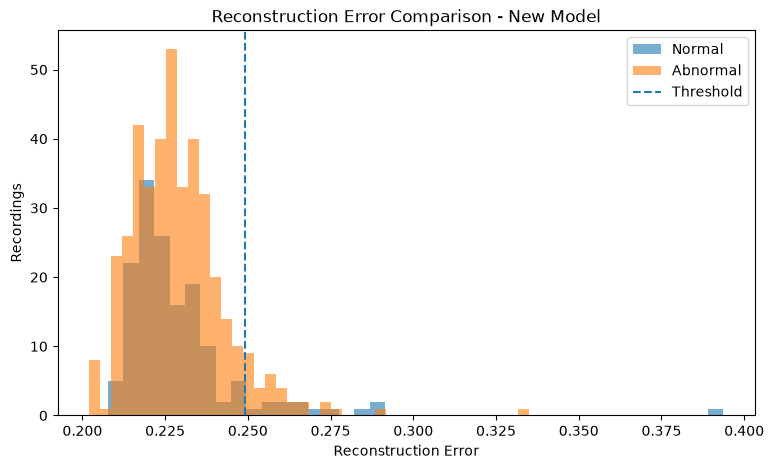

In [32]:
# Separate errors using actual labels
normal_errors = test_errors[y_test == 0]
abnormal_errors = test_errors[y_test == 1]

print("Normal mean:", normal_errors.mean())
print("Abnormal mean:", abnormal_errors.mean())

print("Normal median:", np.median(normal_errors))
print("Abnormal median:", np.median(abnormal_errors))

# Plot distributions
plt.figure(figsize=(9, 5))

plt.hist(normal_errors, bins=40, alpha=0.6, label="Normal")
plt.hist(abnormal_errors, bins=40, alpha=0.6, label="Abnormal")

plt.axvline(threshold, linestyle="--", label="Threshold")

plt.xlabel("Reconstruction Error")
plt.ylabel("Recordings")
plt.title("Reconstruction Error Comparison - New Model")
plt.legend()
plt.show()

In [33]:
# Calculate error for each time frame
val_frame_errors = np.mean(
    np.square(X_val - val_pred),
    axis=(1, 3)
)

test_frame_errors = np.mean(
    np.square(X_test - test_pred),
    axis=(1, 3)
)

# Average the highest 10% frame errors
def top_error_score(errors):
    k = max(1, int(errors.shape[1] * 0.10))
    return np.mean(
        np.sort(errors, axis=1)[:, -k:],
        axis=1
    )

val_scores = top_error_score(val_frame_errors)
test_scores = top_error_score(test_frame_errors)

# Threshold from normal validation recordings
new_threshold = np.percentile(val_scores, 95)

# Predictions
new_predictions = (test_scores > new_threshold).astype(int)

print("New threshold:", new_threshold)
print("Predicted normal:", np.sum(new_predictions == 0))
print("Predicted abnormal:", np.sum(new_predictions == 1))

New threshold: 0.3798792
Predicted normal: 530
Predicted abnormal: 29


In [34]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    new_predictions,
    target_names=["Normal", "Abnormal"]
))

print("New ROC-AUC:", roc_auc_score(y_test, test_scores))

              precision    recall  f1-score   support

      Normal       0.27      0.93      0.41       152
    Abnormal       0.62      0.04      0.08       407

    accuracy                           0.28       559
   macro avg       0.44      0.49      0.25       559
weighted avg       0.52      0.28      0.17       559

New ROC-AUC: 0.5238264580369844


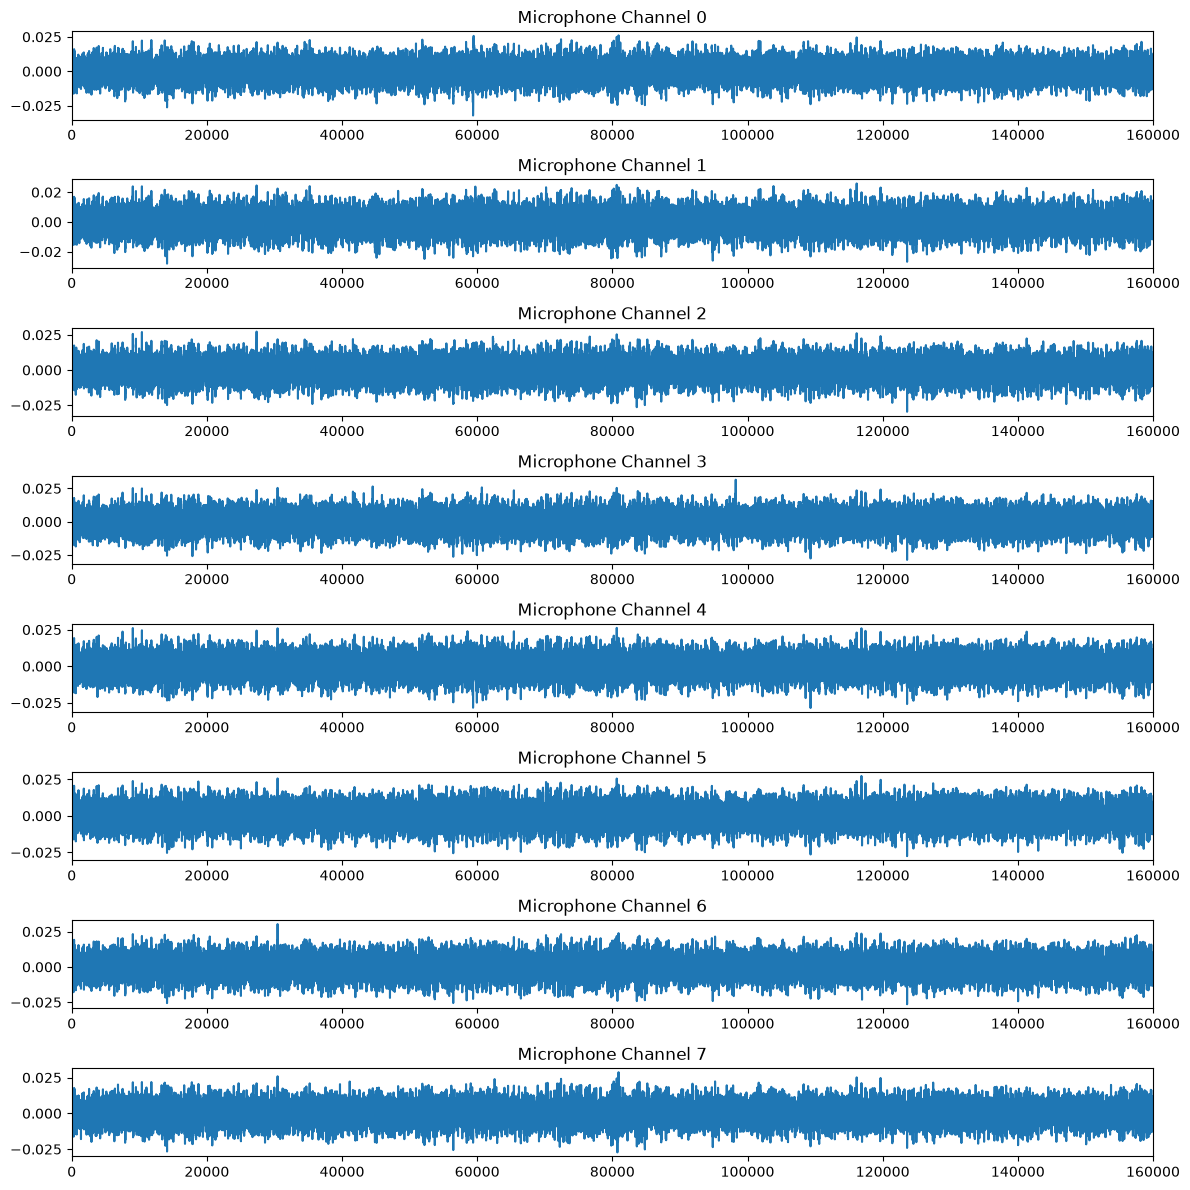

In [35]:
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np

normal_path = train_df.iloc[0]["file_path"]

audio, sr = sf.read(normal_path)

fig, axes = plt.subplots(8, 1, figsize=(12, 12))

for ch in range(8):
    axes[ch].plot(audio[:, ch])
    axes[ch].set_title(f"Microphone Channel {ch}")
    axes[ch].set_xlim(0, len(audio))

plt.tight_layout()
plt.show()

In [36]:
import numpy as np
import soundfile as sf
import pandas as pd

# Load normal and abnormal recordings from id_00
normal_path = next(data_path.glob("id_00/normal/*.wav"))
abnormal_path = next(data_path.glob("id_00/abnormal/*.wav"))

normal_audio, sr = sf.read(normal_path)
abnormal_audio, sr = sf.read(abnormal_path)

# Calculate RMS for each channel
results = []

for ch in range(8):
    normal_rms = np.sqrt(np.mean(normal_audio[:, ch] ** 2))
    abnormal_rms = np.sqrt(np.mean(abnormal_audio[:, ch] ** 2))

    results.append({
        "Channel": ch,
        "Normal RMS": normal_rms,
        "Abnormal RMS": abnormal_rms
    })

df = pd.DataFrame(results)
print(df.round(6))


   Channel  Normal RMS  Abnormal RMS
0        0    0.006316      0.010491
1        1    0.006528      0.010497
2        2    0.006536      0.010011
3        3    0.006487      0.010115
4        4    0.006492      0.009745
5        5    0.006642      0.010514
6        6    0.006669      0.010724
7        7    0.006466      0.010701


In [37]:
import numpy as np
import soundfile as sf
import pandas as pd

normal_files = list(data_path.glob("id_00/normal/*.wav"))[:100]
abnormal_files = list(data_path.glob("id_00/abnormal/*.wav"))[:100]

def calculate_rms(files):
    values = []

    for file in files:
        audio, sr = sf.read(file)

        rms = np.sqrt(np.mean(audio ** 2, axis=0))
        values.append(rms)

    return np.mean(values, axis=0)

normal_rms = calculate_rms(normal_files)
abnormal_rms = calculate_rms(abnormal_files)

comparison = pd.DataFrame({
    "Channel": range(8),
    "Normal RMS": normal_rms,
    "Abnormal RMS": abnormal_rms
})

print(comparison.round(6))

   Channel  Normal RMS  Abnormal RMS
0        0    0.006397      0.010241
1        1    0.006580      0.010481
2        2    0.006465      0.009994
3        3    0.006547      0.009767
4        4    0.006516      0.009352
5        5    0.006608      0.009930
6        6    0.006448      0.010095
7        7    0.006414      0.010175


In [38]:
import random
import numpy as np
import soundfile as sf
from sklearn.metrics import roc_auc_score

random.seed(42)

normal_files = list(data_path.glob("id_00/normal/*.wav"))
abnormal_files = list(data_path.glob("id_00/abnormal/*.wav"))

normal_files = random.sample(normal_files, 100)
abnormal_files = random.sample(abnormal_files, 100)

X_rms = []
y_rms = []

for label, files in [(0, normal_files), (1, abnormal_files)]:
    for file in files:
        audio, sr = sf.read(file)
        rms = np.sqrt(np.mean(audio ** 2, axis=0))

        X_rms.append(rms)
        y_rms.append(label)

X_rms = np.array(X_rms)
y_rms = np.array(y_rms)

for ch in range(8):
    auc = roc_auc_score(y_rms, X_rms[:, ch])
    print(f"Channel {ch} ROC-AUC: {auc:.4f}")

Channel 0 ROC-AUC: 0.7229
Channel 1 ROC-AUC: 0.6979
Channel 2 ROC-AUC: 0.7010
Channel 3 ROC-AUC: 0.7116
Channel 4 ROC-AUC: 0.7312
Channel 5 ROC-AUC: 0.7378
Channel 6 ROC-AUC: 0.7465
Channel 7 ROC-AUC: 0.7406


In [39]:
import soundfile as sf
import numpy as np
from sklearn.metrics import roc_auc_score

channel_features = []

for file in test_df["file_path"]:
    audio, sr = sf.read(file)

    rms = np.sqrt(np.mean(audio ** 2, axis=0))
    channel_features.append(rms)

channel_features = np.array(channel_features)

for ch in range(8):
    auc = roc_auc_score(y_test, channel_features[:, ch])
    print(f"Channel {ch}: ROC-AUC = {auc:.4f}")

ValueError: Found input variables with inconsistent numbers of samples: [559, 2088]

In [40]:
# Select only id_00 test recordings
test_df_id00 = test_df[
    test_df["machine_id"] == "id_00"
].copy()

print("id_00 test recordings:", len(test_df_id00))
print("CNN test recordings:", len(y_test))

id_00 test recordings: 559
CNN test recordings: 559


In [41]:
channel_features = []

for file in test_df_id00["file_path"]:
    audio, sr = sf.read(file)

    rms = np.sqrt(np.mean(audio ** 2, axis=0))
    channel_features.append(rms)

channel_features = np.array(channel_features)

for ch in range(8):
    auc = roc_auc_score(y_test, channel_features[:, ch])
    print(f"Channel {ch}: ROC-AUC = {auc:.4f}")

Channel 0: ROC-AUC = 0.6901
Channel 1: ROC-AUC = 0.6711
Channel 2: ROC-AUC = 0.6673
Channel 3: ROC-AUC = 0.6717
Channel 4: ROC-AUC = 0.6947
Channel 5: ROC-AUC = 0.7083
Channel 6: ROC-AUC = 0.7109
Channel 7: ROC-AUC = 0.7047


In [42]:
# Extract RMS from training and validation recordings
def extract_rms_features(dataframe):
    features = []

    for file in dataframe["file_path"]:
        audio, sr = sf.read(file)
        rms = np.sqrt(np.mean(audio ** 2, axis=0))
        features.append(rms[6])

    return np.array(features)


train_rms = extract_rms_features(train_00)
val_rms = extract_rms_features(val_00)

# Threshold from normal validation recordings
rms_threshold = np.percentile(val_rms, 95)

# Predict test anomalies
rms_predictions = (channel_features[:, 6] > rms_threshold).astype(int)

print("RMS threshold:", rms_threshold)
print("Predicted normal:", np.sum(rms_predictions == 0))
print("Predicted abnormal:", np.sum(rms_predictions == 1))

RMS threshold: 0.007031064890202878
Predicted normal: 349
Predicted abnormal: 210


In [43]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    rms_predictions,
    target_names=["Normal", "Abnormal"]
))

print("RMS ROC-AUC:", roc_auc_score(y_test, channel_features[:, 6]))

              precision    recall  f1-score   support

      Normal       0.42      0.95      0.58       152
    Abnormal       0.97      0.50      0.66       407

    accuracy                           0.62       559
   macro avg       0.69      0.73      0.62       559
weighted avg       0.82      0.62      0.64       559

RMS ROC-AUC: 0.7108657700762964


In [44]:
import librosa
import numpy as np
import soundfile as sf

def extract_features(dataframe):
    features = []

    for file in dataframe["file_path"]:
        audio, sr = sf.read(file)
        audio = audio[:, 6]

        rms = np.mean(librosa.feature.rms(y=audio))
        centroid = np.mean(librosa.feature.spectral_centroid(y=audio, sr=sr))
        bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=audio, sr=sr))
        zcr = np.mean(librosa.feature.zero_crossing_rate(y=audio))

        features.append([rms, centroid, bandwidth, zcr])

    return np.array(features)

X_train_features = extract_features(train_00)
X_val_features = extract_features(val_00)
X_test_features = extract_features(test_00)

print(X_train_features.shape)
print(X_test_features.shape)

AttributeError: module 'numba' has no attribute 'core'

In [45]:
import numba
print(numba.__version__)
print(numba.__file__)

0.68.1
c:\Users\hanum\dl-env\Lib\site-packages\numba\__init__.py


In [46]:
python -m pip uninstall numba -y
python -m pip install numba

SyntaxError: invalid syntax (1758186626.py, line 1)

In [47]:
import numba
import librosa
import numpy as np

print(numba.__version__)

audio = np.random.randn(16000)
print(librosa.feature.zero_crossing_rate(y=audio).shape)

0.68.1


AttributeError: module 'numba' has no attribute 'core'

In [48]:
import numpy as np
import librosa
import soundfile as sf

def extract_features(dataframe):
    features = []

    for file in dataframe["file_path"]:
        audio, sr = sf.read(file)
        audio = audio[:, 6]

        rms = np.mean(librosa.feature.rms(y=audio))

        centroid = np.mean(
            librosa.feature.spectral_centroid(y=audio, sr=sr)
        )

        bandwidth = np.mean(
            librosa.feature.spectral_bandwidth(y=audio, sr=sr)
        )

        # Calculate ZCR manually without Numba
        zcr = np.mean(np.abs(np.diff(np.sign(audio)))) / 2

        features.append([rms, centroid, bandwidth, zcr])

    return np.array(features)


X_train_features = extract_features(train_00)
X_val_features = extract_features(val_00)
X_test_features = extract_features(test_00)

print(X_train_features.shape)
print(X_val_features.shape)
print(X_test_features.shape)

(707, 4)
(152, 4)
(559, 4)


In [49]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score

# Train using normal machine sounds only
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

model.fit(X_train_features)

# Anomaly scores: higher means more abnormal
val_scores = -model.score_samples(X_val_features)
test_scores = -model.score_samples(X_test_features)

# Set threshold using normal validation data
threshold = np.percentile(val_scores, 95)

# Predict: 0 = Normal, 1 = Abnormal
predictions = (test_scores > threshold).astype(int)

print("Threshold:", threshold)

print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Abnormal"]
))

print("ROC-AUC:", roc_auc_score(y_test, test_scores))

ImportError: DLL load failed while importing _sag_fast: An Application Control policy has blocked this file.

In [50]:
import sklearn
print(sklearn.__version__)

from sklearn.metrics import roc_auc_score
print("Metrics working")

1.9.1
Metrics working


In [52]:
from sklearn.ensemble import IsolationForest

print("Isolation Forest imported successfully")

Isolation Forest imported successfully


In [53]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# Train only on normal audio features
model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

model.fit(X_train_features)

# Calculate anomaly scores
val_scores = -model.score_samples(X_val_features)
test_scores = -model.score_samples(X_test_features)

# Threshold from normal validation data
threshold = np.percentile(val_scores, 95)

# Predictions: 0 = Normal, 1 = Abnormal
predictions = (test_scores > threshold).astype(int)

print("Threshold:", threshold)

print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Abnormal"]
))

print("ROC-AUC:", roc_auc_score(y_test, test_scores))

Threshold: 0.5631495568375886
              precision    recall  f1-score   support

      Normal       0.39      0.91      0.55       152
    Abnormal       0.93      0.47      0.63       407

    accuracy                           0.59       559
   macro avg       0.66      0.69      0.59       559
weighted avg       0.79      0.59      0.61       559

ROC-AUC: 0.8257629639208588


In [54]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save trained model
joblib.dump(model, "models/isolation_forest.pkl")

# Save threshold
joblib.dump(threshold, "models/threshold.pkl")

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


In [55]:
import joblib

model = joblib.load("models/isolation_forest.pkl")
threshold = joblib.load("models/threshold.pkl")

print("Model loaded!")
print("Threshold:", threshold)

Model loaded!
Threshold: 0.5631495568375886


In [56]:
import soundfile as sf
import numpy as np
import librosa
import joblib

# Select one audio file
audio, sr = sf.read(test_00.iloc[0]["file_path"])
audio = audio[:, 6]

# Extract the same 4 features
rms = np.mean(librosa.feature.rms(y=audio))
centroid = np.mean(librosa.feature.spectral_centroid(y=audio, sr=sr))
bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=audio, sr=sr))
zcr = np.mean(np.abs(np.diff(np.sign(audio)))) / 2

features = np.array([[rms, centroid, bandwidth, zcr]])

# Load saved model and threshold
model = joblib.load("models/isolation_forest.pkl")
threshold = joblib.load("models/threshold.pkl")

# Predict
score = -model.score_samples(features)[0]
prediction = "Abnormal" if score > threshold else "Normal"

print("Anomaly Score:", score)
print("Prediction:", prediction)

Anomaly Score: 0.5059712830092639
Prediction: Normal
